In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("social_media_engagement_5000.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [2]:

# Check dataset columns
print("Column Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()


Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']

Data Types:
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  --

In [3]:

# Convert posted_at column to datetime

df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')

# Check updated data type
print("Updated Date Data Type:")
print(df['posted_at'].dtype)

# Display first 5 dates
display(df[['posted_at']].head())


Updated Date Data Type:
datetime64[us]


C:\Users\lenovo\AppData\Local\Temp\ipykernel_11164\3920957630.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')


,posted_at
0,2022-12-17
1,2023-06-02
2,2023-05-07
3,2023-02-12
4,2023-05-23


In [4]:

# Convert likes column into NumPy array

likes_array = df['likes'].to_numpy()

# Basic NumPy operations
print("Likes Array:")
print(likes_array[:10])

print("\nTotal Likes:", np.sum(likes_array))
print("Average Likes:", np.mean(likes_array))
print("Maximum Likes:", np.max(likes_array))
print("Minimum Likes:", np.min(likes_array))


Likes Array:
[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611.    nan 14106.]

Total Likes: nan
Average Likes: nan
Maximum Likes: nan
Minimum Likes: nan


In [5]:

# NumPy operations handling missing values

print("Total Likes:", np.nansum(likes_array))
print("Average Likes:", np.nanmean(likes_array))
print("Maximum Likes:", np.nanmax(likes_array))
print("Minimum Likes:", np.nanmin(likes_array))


Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


In [6]:

# Check missing values in the dataset

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isna().sum().sum())


Missing Values in Each Column:
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Total Missing Values:
900


In [7]:

# Handle missing numerical values using median

numeric_columns = ['age', 'likes', 'comments', 'shares']

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values using mode

categorical_columns = ['gender', 'sentiment']

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify missing values after cleaning

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values After Cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

Total Missing Values: 0


In [8]:

# Check duplicate records

print("Total Duplicate Rows:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("\nDataset Shape After Removing Duplicates:")
print(df.shape)

print("\nDuplicates Remaining:")
print(df.duplicated().sum())


Total Duplicate Rows:
0

Dataset Shape After Removing Duplicates:
(5000, 19)

Duplicates Remaining:
0


In [9]:

# Check unique category values

print("Gender Values:")
print(df['gender'].unique())

print("\nSentiment Values:")
print(df['sentiment'].unique())

print("\nPost Type Values:")
print(df['post_type'].unique())

print("\nDevice Type Values:")
print(df['device_type'].unique())


Gender Values:
<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str

Sentiment Values:
<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

Post Type Values:
<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

Device Type Values:
<StringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str


In [10]:

# Standardize text categories

columns_to_clean = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for col in columns_to_clean:
    df[col] = df[col].str.strip().str.lower()

print("Categories after standardization:")

for col in columns_to_clean:
    print(f"\n{col}:")
    print(df[col].unique())


Categories after standardization:

gender:
<StringArray>
['female', 'male', 'other']
Length: 3, dtype: str

country:
<StringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: str

post_type:
<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

post_category:
<StringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str

device_type:
<StringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str

sentiment:
<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


In [11]:

# Check numerical values

print("Likes, Comments and Shares Statistics:")
display(df[['likes', 'comments', 'shares']].describe())

# Check negative values
print("\nNegative Values:")
print((df[['likes', 'comments', 'shares']] < 0).sum())


Likes, Comments and Shares Statistics:


,likes,comments,shares
count,5000.000000,5000.000000,5000.0000
mean,10106.997400,1502.039800,1002.9106
std,5702.293017,856.393312,570.8552
min,10.000000,0.000000,0.0000
25%,5235.000000,792.000000,511.0000
50%,10105.500000,1497.000000,1012.0000
75%,14959.000000,2235.250000,1483.0000
max,19998.000000,2999.000000,1999.0000



Negative Values:
likes       0
comments    0
shares      0
dtype: int64


In [12]:

# Display hashtag samples

print("Sample Hashtag Values:")
display(df[['hashtags']].head(10))


Sample Hashtag Values:


,hashtags
0,#foodie #travel #love
1,#fitness
2,#foodie
3,#music #foodie #fun
4,#travel
5,#fitness
6,#music
7,#travel #music #fitness
8,#music #fun #fitness
9,#lifestyle #love


In [13]:

# Extract hashtag count

df['hashtag_count'] = df['hashtags'].str.count('#')

# Display hashtag count
print("Hashtag Count:")
display(df[['hashtags', 'hashtag_count']].head(10))

# Average hashtag count
print("\nAverage Hashtag Count:")
print(df['hashtag_count'].mean())


Hashtag Count:


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2



Average Hashtag Count:
1.9986


In [14]:

# Dataset Structure

print("First 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe())


First 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1



Last 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3



Dataset Shape:
(5000, 20)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [15]:

# Categorical Data Analysis

print("Gender Distribution:")
print(df['gender'].value_counts())

print("\nPost Type Distribution:")
print(df['post_type'].value_counts())

print("\nCountry Distribution:")
print(df['country'].value_counts())

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

print("\nUnique Post Categories:")
print(df['post_category'].unique())

print("\nNumber of Unique Countries:")
print(df['country'].nunique())


Gender Distribution:
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Country Distribution:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64

Sentiment Distribution:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

Unique Post Categories:
<StringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str

Number of Unique Countries:
10


In [16]:

# Correlation Matrix

numeric_df = df.select_dtypes(include=np.number)

# Remove ID columns from correlation analysis
numeric_df = numeric_df.drop(
    columns=['user_id', 'post_id'],
    errors='ignore'
)

correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix)


Correlation Matrix:


,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
age,1.000000,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
likes,-0.036322,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.007284,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013871,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,0.005542,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.013322,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,-0.024894,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,0.008039,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319
hashtag_count,0.007173,-0.002190,-0.015230,0.013379,-0.023301,-0.002714,0.008802,0.005319,1.000000


In [17]:

# 1. Average Likes by Post Type

print("Average Likes by Post Type:")
display(df.groupby('post_type')['likes'].mean().sort_values(ascending=False))

# 2. Average Impressions by Country

print("\nAverage Impressions by Country:")
display(df.groupby('country')['impression_count'].mean().sort_values(ascending=False))

# 3. Average Engagement Rate by Sentiment

print("\nAverage Engagement Rate by Sentiment:")
display(df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False))

# 4. Average Likes by Post Category

print("\nAverage Likes by Post Category:")
display(df.groupby('post_category')['likes'].mean().sort_values(ascending=False))


Average Likes by Post Type:


post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64


Average Impressions by Country:


country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64


Average Engagement Rate by Sentiment:


sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64


Average Likes by Post Category:


post_category
food         10225.522766
music        10205.749606
travel       10196.304167
lifestyle    10180.559308
tech         10171.571429
education    10126.487322
fitness       9914.602222
fashion       9843.356902
Name: likes, dtype: float64

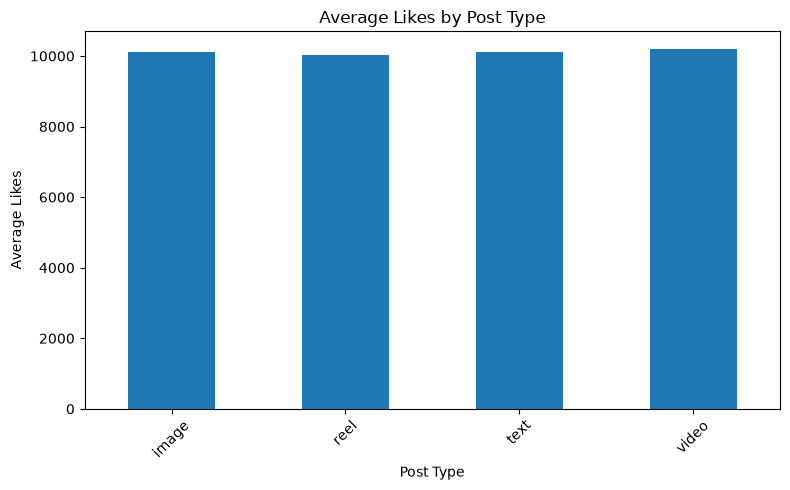

In [18]:

import matplotlib.pyplot as plt

# Average Likes by Post Type
avg_likes = df.groupby('post_type')['likes'].mean()

plt.figure(figsize=(8, 5))
avg_likes.plot(kind='bar')
plt.title('Average Likes by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


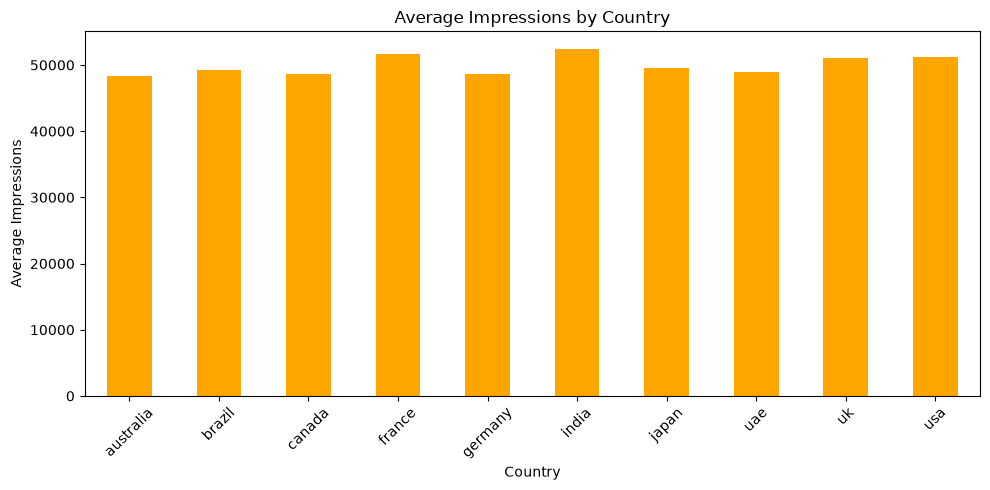

In [19]:

# Average Impressions by Country

avg_impressions = df.groupby('country')['impression_count'].mean()

plt.figure(figsize=(10, 5))
avg_impressions.plot(kind='bar', color='orange')

plt.title('Average Impressions by Country')
plt.xlabel('Country')
plt.ylabel('Average Impressions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


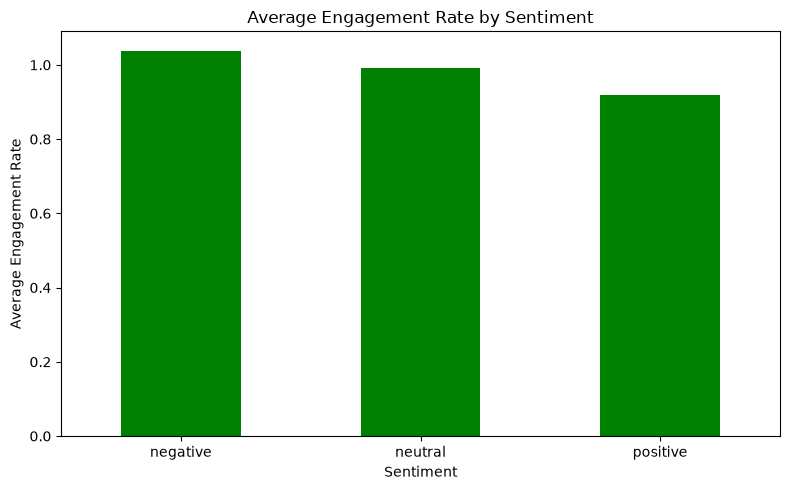

In [20]:

# Average Engagement Rate by Sentiment

avg_engagement = df.groupby('sentiment')['engagement_rate'].mean()

plt.figure(figsize=(8, 5))
avg_engagement.plot(kind='bar', color='green')

plt.title('Average Engagement Rate by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


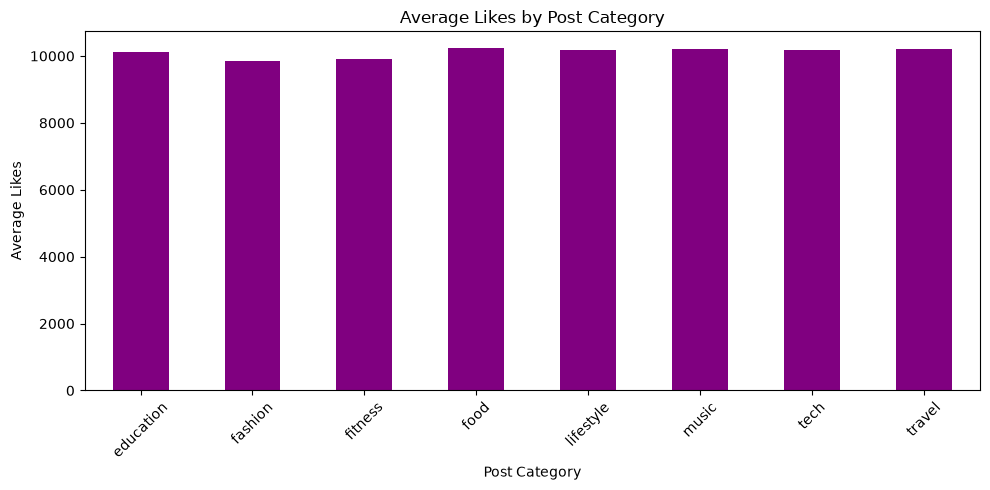

In [21]:

# Average Likes by Post Category

avg_category_likes = df.groupby('post_category')['likes'].mean()

plt.figure(figsize=(10, 5))
avg_category_likes.plot(kind='bar', color='purple')

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


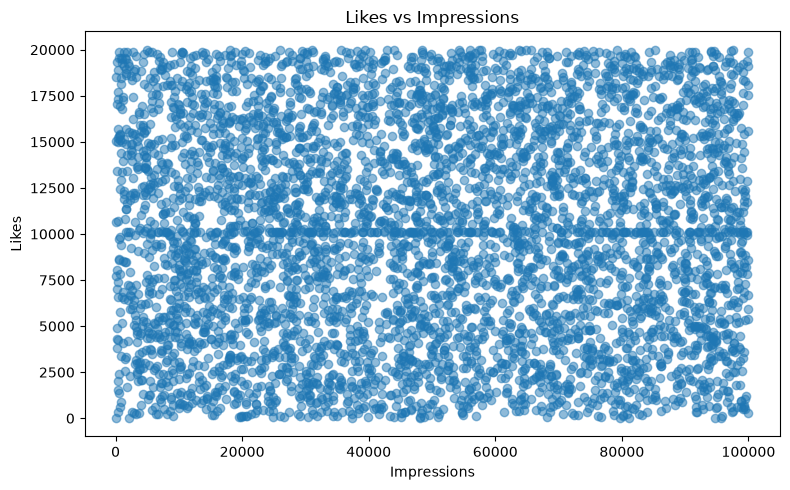

In [22]:

# Scatter Plot: Likes vs Impressions

plt.figure(figsize=(8, 5))

plt.scatter(df['impression_count'], df['likes'], alpha=0.5)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.tight_layout()
plt.show()


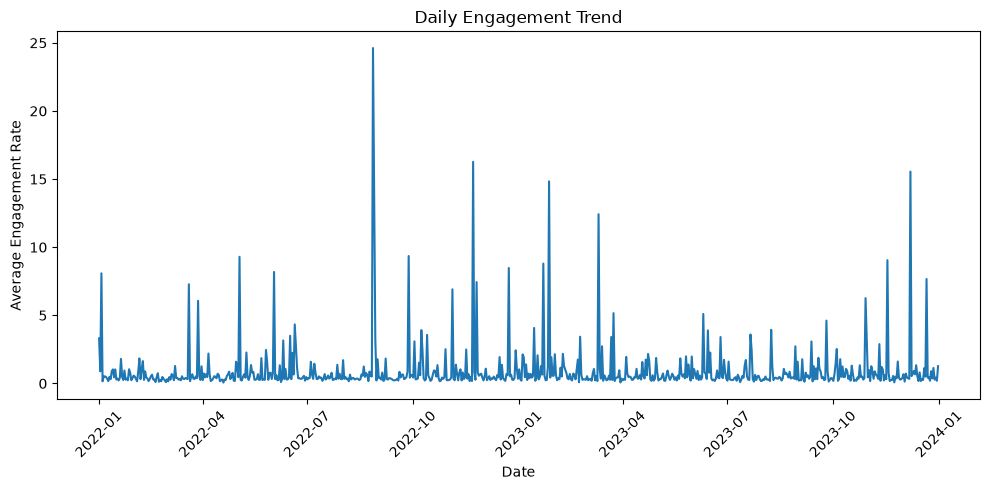

In [23]:

# Line Chart: Daily Engagement Trend

df['posted_at'] = pd.to_datetime(df['posted_at'])

daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_rate'].mean()

plt.figure(figsize=(10, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


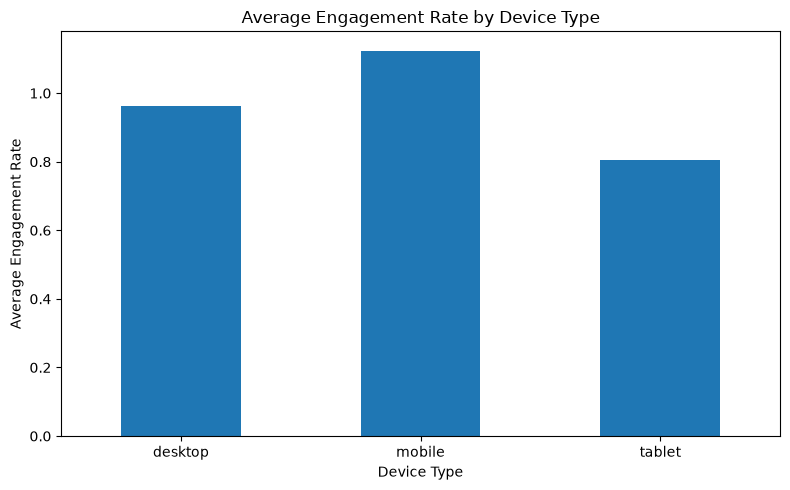

In [24]:

# Bar Chart: Engagement Rate by Device Type

device_engagement = df.groupby('device_type')['engagement_rate'].mean()

plt.figure(figsize=(8, 5))
device_engagement.plot(kind='bar')

plt.title('Average Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


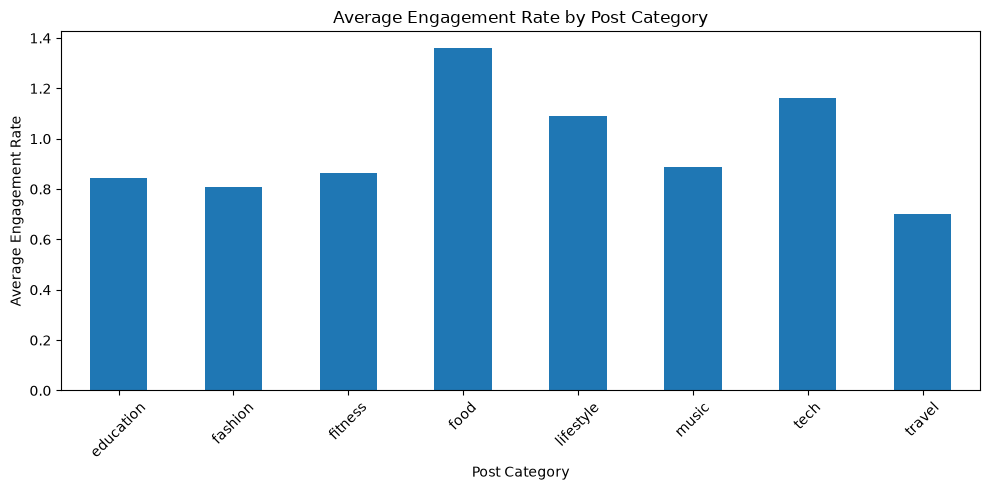

In [25]:
# Bar Chart: Engagement Rate by Post Category

category_engagement = df.groupby('post_category')['engagement_rate'].mean()

plt.figure(figsize=(10, 5))
category_engagement.plot(kind='bar')

plt.title('Average Engagement Rate by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

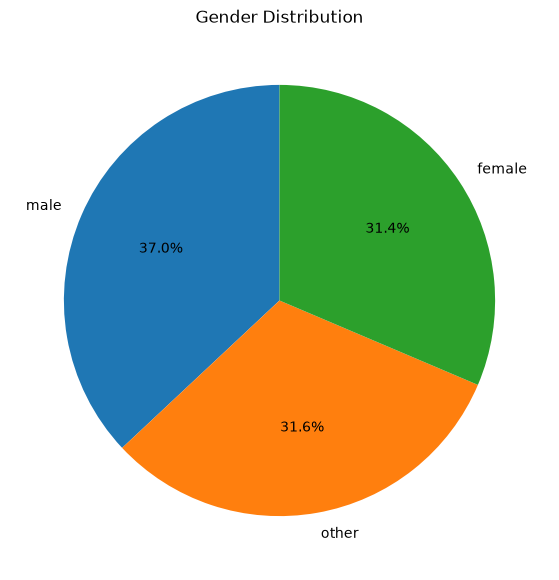

In [26]:
# Pie Chart: Gender Distribution

gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(gender_counts, labels=gender_counts.index,
        autopct='%1.1f%%', startangle=90)

plt.title('Gender Distribution')
plt.show()

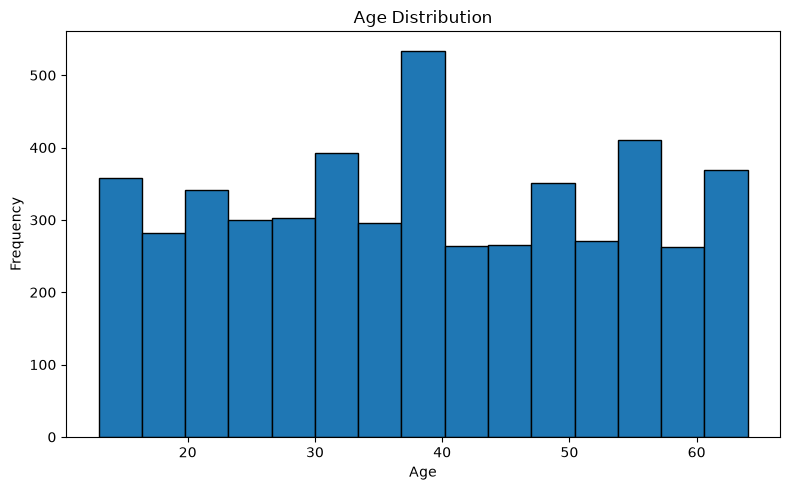

In [27]:
# Histogram: Age Distribution

plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

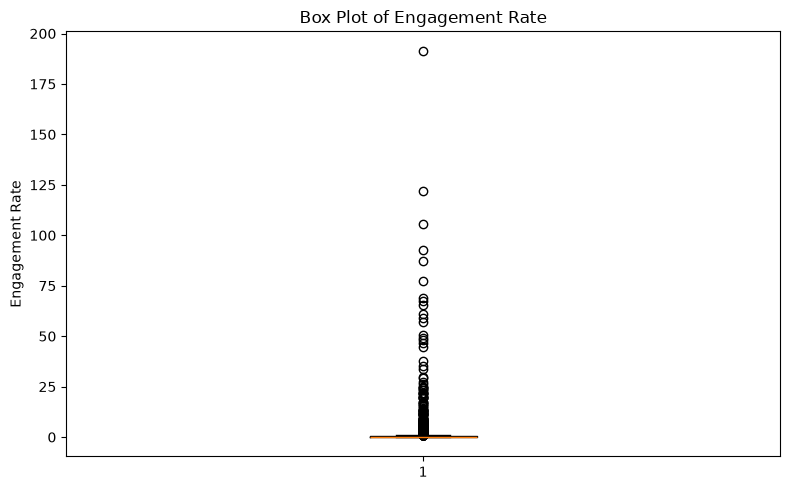

In [28]:
# Box Plot: Engagement Rate

plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'])

plt.title('Box Plot of Engagement Rate')
plt.ylabel('Engagement Rate')

plt.tight_layout()
plt.show()